In [1]:
import os, math, time, random
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import torch.optim as optim
from torchvision import transforms, utils as vutils
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

Device: mps


In [2]:
class PrepareDataset(Dataset):
    """Loads A|B image pairs and splits them into edges (A) and photo (B)."""
    def __init__(self, root, split="train", size=256, hflip=True, in_ch="auto"):
        self.root = Path(root) / split
        self.paths = sorted([p for p in self.root.iterdir()
                             if p.suffix.lower() in {".jpg", ".png", ".jpeg"}])
        self.size = size
        self.hflip = hflip
        self.in_ch = in_ch

        self.resize = transforms.Resize((size, size),
                                        interpolation=transforms.InterpolationMode.BICUBIC)
        self.to_tensor = transforms.ToTensor()
        self.norm1 = transforms.Normalize([0.5], [0.5])
        self.norm3 = transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])

    def __len__(self):
        return len(self.paths)

    def _split_ab(self, img):
        w, h = img.size
        A = img.crop((0, 0, w // 2, h))   # left half: edges
        B = img.crop((w // 2, 0, w, h))   # right half: photo
        return A, B

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        A_img, B_img = self._split_ab(img)

        A_img = self.resize(A_img)
        B_img = self.resize(B_img)

        if self.hflip and random.random() < 0.5:
            A_img = A_img.transpose(Image.FLIP_LEFT_RIGHT)
            B_img = B_img.transpose(Image.FLIP_LEFT_RIGHT)

        if self.in_ch == 1:
            A_t = transforms.functional.rgb_to_grayscale(self.to_tensor(A_img),
                                                         num_output_channels=1)
            A_t = self.norm1(A_t)
        else:
            A_t = self.norm3(self.to_tensor(A_img))

        B_t = self.norm3(self.to_tensor(B_img))
        return A_t, B_t

In [3]:
root = "./edges2shoes"

train_ds = PrepareDataset(root, split="train", size=256, hflip=True, in_ch=3)
val_ds = PrepareDataset(root, split="val", size=256, hflip=False, in_ch=3)

# Use a subset so training finishes in reasonable time on a Mac
train_ds = Subset(train_ds, range(5000))

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=0)

print("Dataset sizes:", len(train_ds), "training,", len(val_ds), "validation")

Dataset sizes: 5000 training, 200 validation


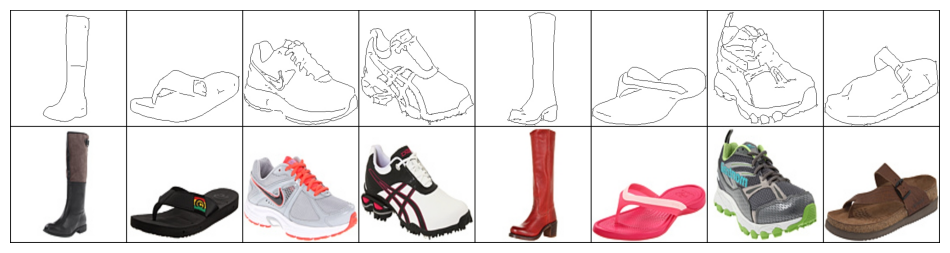

In [4]:
A, B = next(iter(train_loader))
grid = vutils.make_grid(torch.cat([(A[:8] + 1) / 2, (B[:8] + 1) / 2], dim=0), nrow=8)
plt.figure(figsize=(12, 4))
plt.axis("off")
plt.imshow(grid.permute(1, 2, 0).cpu())
plt.show()

In [6]:
def conv_block(in_c, out_c, k=4, s=2, p=1, norm=True, activation='lrelu'):
    """Conv2d -> (InstanceNorm) -> LeakyReLU/ReLU"""
    layers = [nn.Conv2d(in_c, out_c, kernel_size=k, stride=s, padding=p, bias=not norm)]
    if norm:
        layers.append(nn.InstanceNorm2d(out_c))
    if activation == 'lrelu':
        layers.append(nn.LeakyReLU(0.2, inplace=True))
    elif activation == 'relu':
        layers.append(nn.ReLU(inplace=True))
    return nn.Sequential(*layers)


def deconv_block(in_c, out_c, k=4, s=2, p=1, dropout=False):
    """ConvTranspose2d -> InstanceNorm -> ReLU -> (Dropout)"""
    layers = [
        nn.ConvTranspose2d(in_c, out_c, kernel_size=k, stride=s, padding=p, bias=False),
        nn.InstanceNorm2d(out_c),
        nn.ReLU(inplace=True),
    ]
    if dropout:
        layers.append(nn.Dropout(0.5))
    return nn.Sequential(*layers)

In [7]:
class UNetGenerator(nn.Module):
    def __init__(self, in_ch=3, out_ch=3, nf=64):
        super().__init__()
        # Encoder
        self.e1 = conv_block(in_ch, nf, norm=False)
        self.e2 = conv_block(nf, nf * 2)
        self.e3 = conv_block(nf * 2, nf * 4)
        self.e4 = conv_block(nf * 4, nf * 8)
        self.e5 = conv_block(nf * 8, nf * 8)
        self.e6 = conv_block(nf * 8, nf * 8, norm=False)   # bottleneck
        # Decoder
        self.d1 = deconv_block(nf * 8, nf * 8, dropout=True)
        self.d2 = deconv_block(nf * 16, nf * 8, dropout=True)
        self.d3 = deconv_block(nf * 16, nf * 4)
        self.d4 = deconv_block(nf * 8, nf * 2)
        self.d5 = deconv_block(nf * 4, nf)
        self.d6 = nn.Sequential(
            nn.ConvTranspose2d(nf * 2, out_ch, kernel_size=4, stride=2, padding=1),
            nn.Tanh())

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.e4(e3)
        e5 = self.e5(e4)
        e6 = self.e6(e5)

        d1 = torch.cat([self.d1(e6), e5], dim=1)
        d2 = torch.cat([self.d2(d1), e4], dim=1)
        d3 = torch.cat([self.d3(d2), e3], dim=1)
        d4 = torch.cat([self.d4(d3), e2], dim=1)
        d5 = torch.cat([self.d5(d4), e1], dim=1)
        return self.d6(d5)

In [8]:
class PatchDiscriminator(nn.Module):
    def __init__(self, in_ch=6, nf=64):
        super().__init__()
        self.c1 = conv_block(in_ch, nf, norm=False)
        self.c2 = conv_block(nf, nf * 2)
        self.c3 = conv_block(nf * 2, nf * 4)
        self.c4 = conv_block(nf * 4, nf * 8, s=1)
        self.c5 = nn.Conv2d(nf * 8, 1, kernel_size=4, stride=1, padding=1)

    def forward(self, a, b):
        x = torch.cat([a, b], dim=1)   # 6 channels: edge + photo
        x = self.c1(x)
        x = self.c2(x)
        x = self.c3(x)
        x = self.c4(x)
        return self.c5(x)              # [batch, 1, 30, 30]

In [9]:
G = UNetGenerator().to(device)
D = PatchDiscriminator().to(device)

criterion_gan = nn.BCEWithLogitsLoss()
criterion_l1 = nn.L1Loss()

lr = 2e-4
beta1, beta2 = 0.5, 0.999
opt_G = optim.Adam(G.parameters(), lr=lr, betas=(beta1, beta2))
opt_D = optim.Adam(D.parameters(), lr=lr, betas=(beta1, beta2))

lambda_L1 = 100.0

# Quick check: does a batch go through both models?
with torch.no_grad():
    test_out = G(A.to(device))
    test_d = D(A.to(device), test_out)
print("Generator output:", test_out.shape)
print("Discriminator output:", test_d.shape)

Generator output: torch.Size([8, 3, 256, 256])
Discriminator output: torch.Size([8, 1, 30, 30])


In [10]:
def save_sample(a, fake_b, out_path, b=None):
    """Saves a grid: edges, (real), fake for the first 8 samples."""
    a_ = (a[:8].cpu() + 1) / 2.0
    f_ = (fake_b[:8].detach().cpu() + 1) / 2.0
    if b is not None:
        b_ = (b[:8].cpu() + 1) / 2.0
        grid = vutils.make_grid(torch.cat([a_, b_, f_], dim=0), nrow=8, padding=2)
    else:
        grid = vutils.make_grid(torch.cat([a_, f_], dim=0), nrow=8, padding=2)
    vutils.save_image(grid, out_path)

In [11]:
epochs = 5   # lab says 12; start smaller on a Mac
outdir = Path("./pix2pix_runs")
outdir.mkdir(parents=True, exist_ok=True)

for epoch in range(1, epochs + 1):
    G.train()
    D.train()
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{epochs}")
    running_G, running_D = 0.0, 0.0

    for i, (a, b) in enumerate(pbar):
        a, b = a.to(device), b.to(device)

        # ---- Update Discriminator ----
        opt_D.zero_grad(set_to_none=True)
        pred_real = D(a, b)
        valid = torch.ones_like(pred_real)
        loss_D_real = criterion_gan(pred_real, valid)

        with torch.no_grad():
            fake_b = G(a)
        pred_fake = D(a, fake_b)
        fake = torch.zeros_like(pred_fake)
        loss_D_fake = criterion_gan(pred_fake, fake)

        loss_D = 0.5 * (loss_D_real + loss_D_fake)
        loss_D.backward()
        opt_D.step()

        # ---- Update Generator ----
        opt_G.zero_grad(set_to_none=True)
        fake_b = G(a)
        pred_fake_for_G = D(a, fake_b)
        loss_G_adv = criterion_gan(pred_fake_for_G, valid)
        loss_G_L1 = criterion_l1(fake_b, b) * lambda_L1
        loss_G = loss_G_adv + loss_G_L1
        loss_G.backward()
        opt_G.step()

        running_G += loss_G.item()
        running_D += loss_D.item()
        pbar.set_postfix(G=running_G / (i + 1), D=running_D / (i + 1))

    # ---- End of epoch: save samples and checkpoints ----
    G.eval()
    with torch.no_grad():
        a_val, b_val = next(iter(val_loader))
        a_val, b_val = a_val.to(device), b_val.to(device)
        fake_val = G(a_val)
        save_sample(a_val, fake_val, outdir / f"epoch_{epoch:03d}.png", b=b_val)

    torch.save(G.state_dict(), outdir / f"G_epoch_{epoch:03d}.pt")
    torch.save(D.state_dict(), outdir / f"D_epoch_{epoch:03d}.pt")

print("Training finished. Check samples in", outdir)

Epoch 1/5:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 2/5:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 3/5:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 4/5:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 5/5:   0%|          | 0/625 [00:00<?, ?it/s]

Training finished. Check samples in pix2pix_runs


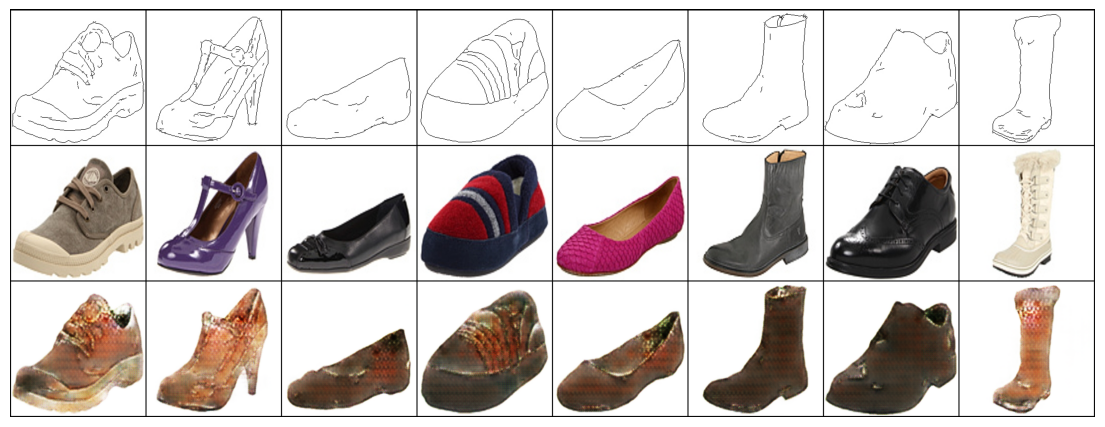

In [12]:
img = Image.open(outdir / f"epoch_{epochs:03d}.png")
plt.figure(figsize=(14, 6))
plt.imshow(img)
plt.axis("off")
plt.show()